# 01 Caractéristiques des images d'arachide

Objectif : décrire les images avant tout traitement, choisir les prétraitements.

- 36 667 images d'arachide, 4 groupes capteur / site / campagne.
- Mesures par image sur la zone utile (sans les bandes du 120 DPI) : `src/prmi/image_stats.py`.
- Caches : `data/interim/image_stats.parquet` (une ligne par image), `data/interim/image_means.npz` (image moyenne en gris par groupe, calculée sur le split train seul). Calculs, clé branchée : `PYTHONPATH=src python -m prmi.image_stats` (environ 20 min) et `... prmi.image_stats means` (quelques minutes).

**Cadre : on simule un projet client.** PRMI est un jeu public, déjà découpé en train, val et test. On s'impose volontairement les règles d'un vrai projet :
- on dispose des images de train et de val ;
- le test joue le rôle d'images futures : ni pour estimer le prétraitement, ni pour le vérifier, ni pour régler le modèle, seulement pour l'évaluation finale ;
- les paramètres calculés sur plusieurs images (fond moyen) sont estimés sur le train et vérifiés sur le val ; la normalisation par image n'en a pas.

Limite : l'exploration descriptive ci-dessous porte sur toutes les images, test compris. Les sessions et les sites sont partagés entre les splits (seuls les tubes sont séparés) : les conclusions seraient les mêmes sur train et val, mais c'est une entorse à la règle.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / 'src'))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image

from prmi import viz
from prmi.image_stats import compare_conversions, load_image_stats, load_mean_images
from prmi.inventory import RAW
from prmi.preprocess import crop_for, flatfield, preprocess

viz.apply_style()
pd.set_option('display.width', 180)
%config InlineBackend.figure_formats = ['jpeg']
plt.rcParams['figure.dpi'] = 60

d = load_image_stats()
means = load_mean_images()
G = viz.GROUPS
print(d.shape)

(36667, 48)


## 1. Images disponibles

In [2]:
# Répartition par split et part d'images avec racine, en % des images de chaque groupe
t = (100 * pd.crosstab(d['group'], d['split'], normalize='index')).loc[G, ['train', 'val', 'test']]
t.insert(0, 'total (images)', d.groupby('group').size())
t['avec racine'] = 100 * d.groupby('group')['has_root'].mean()
t.round(1)

split,total (images),train,val,test,avec racine
group,,,,,
150 BAZ 2015,11240,59.3,16.7,24.1,49.1
150 BAZ 2016,7289,57.6,17.5,24.9,67.6
150 CZ 2016,1096,57.1,18.2,24.6,64.5
120 EED 2017,17042,59.2,20.0,20.8,49.9


- 150 DPI : 19 625 images (entraînement). 120 DPI : 17 042 images (test d'un capteur à l'autre).
- CZ 2016 : petit groupe (1 096 images, une seule date).

## 2. Bords et bandes

In [3]:
# 120 DPI : moyenne et écart-type de chaque bande, sur toutes les images
bands = [c for c in d.columns if c.startswith('band_')]
d.loc[d['dpi'] == 120, bands].describe().loc[['mean', 'min', 'max']].round(1)

,band_left_mean,band_left_std,band_top_mean,band_top_std,band_bottom_mean,band_bottom_std
mean,240.0,0.1,242.6,4.2,11.7,41.4
min,240.0,0.0,239.6,2.7,7.3,37.2
max,240.0,0.2,243.8,6.3,17.7,57.9


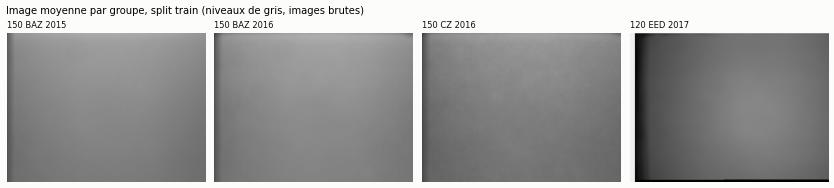

In [4]:
fig, axes = plt.subplots(1, 4, figsize=(14, 3.2))
for ax, g in zip(axes, G):
    ax.imshow(means[g], cmap='gray', vmin=0, vmax=255)
    ax.set_title(g, loc='left', fontsize=10)
    ax.axis('off')
fig.suptitle('Image moyenne par groupe, split train (niveaux de gris, images brutes)', x=0.01, ha='left')
fig.tight_layout()
viz.save(fig, '01_images_moyennes.png')

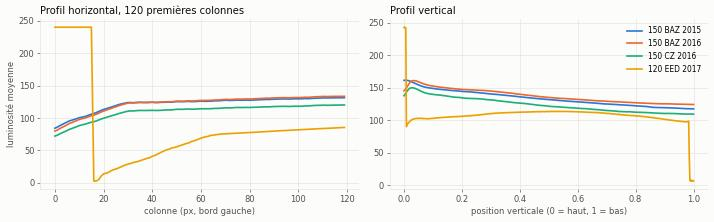

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for g in G:
    m = means[g]
    axes[0].plot(np.arange(120), m[:, :120].mean(0), color=viz.GROUP_COLORS[g], lw=2, label=g)
    axes[1].plot(np.linspace(0, 1, m.shape[0]), m.mean(1), color=viz.GROUP_COLORS[g], lw=2, label=g)
axes[0].set_xlabel('colonne (px, bord gauche)')
axes[0].set_ylabel('luminosité moyenne')
axes[0].set_title('Profil horizontal, 120 premières colonnes', loc='left')
axes[1].set_xlabel('position verticale (0 = haut, 1 = bas)')
axes[1].set_title('Profil vertical', loc='left')
axes[1].legend(frameon=False, fontsize=9)
fig.tight_layout()
viz.save(fig, '01_profils_bords.png')

- 120 DPI, bandes de remplissage identiques sur les 17 042 images :
  - gauche, colonnes 0 à 15 : blanc (240, écart-type nul) ; colonnes 16 à 18 : noir quasi constant ;
  - haut, lignes 0 à 3 : blanc (243) ; bas, lignes 472 à 479 : noir.
  - = le pic à 240 de l'histogramme.
- Après les bandes, dégradé de gauche à droite sur les deux capteurs, stable d'une image à l'autre :
  - 120 DPI : très marqué, bord gauche presque noir, remonte sur une centaine de colonnes (rapport tiers gauche / tiers droit : 0,68) ;
  - 150 DPI : moins marqué (rapport 0,96 ; bord gauche à 80 contre 125 au centre, sur environ 30 colonnes), mais présent. Gêne aussi : dégradé vertical, haut plus clair (rapport 1,2).
- Racines visibles dans la zone sombre du 120 DPI (masques 10 fois moins denses sur les colonnes 16 à 35 : sous-annotées) → ne pas couper plus que le remplissage.

**Décision** :
1. recadrage du 120 DPI : lignes 4 à 471, colonnes 24 à 639 (616 x 468), mêmes indices sur les masques ;
2. correction du fond par l'image moyenne du groupe, pour les deux capteurs (test ci-dessous).

### Prétraitement testé : recadrage et correction du fond

Code : `src/prmi/preprocess.py` (`crop_for`, `flatfield`, `preprocess`).

- Recadrage : 120 DPI seulement.
- Principe de la correction : le contenu (sol, racines) change d'une image à l'autre, le dégradé d'éclairage non. La moyenne de plusieurs milliers d'images efface le contenu et ne garde que le dégradé.
- Fond (`flatfield`), pour chaque groupe :
  1. image moyenne du groupe (cache `image_means.npz`, split train seul : pas de fuite vers val et test), recadrée ;
  2. flou léger, σ = 4 px (σ = 20 px surcorrige le coude du dégradé, voir plus bas) ;
  3. division par la luminosité du quart central : fond = 1 au centre, < 1 sur les bords assombris ;
  4. plancher à 1/8 : gain plafonné à ×8, pour ne pas amplifier le bruit des premières colonnes.
- Correction (`preprocess`) : recadrage, puis division de chaque pixel par le fond de sa position (même fond pour les 3 canaux). Un pixel à 60 là où le fond vaut 0,6 devient 100.
- Un fond par groupe : les 3 groupes 150 DPI ont chacun le leur.

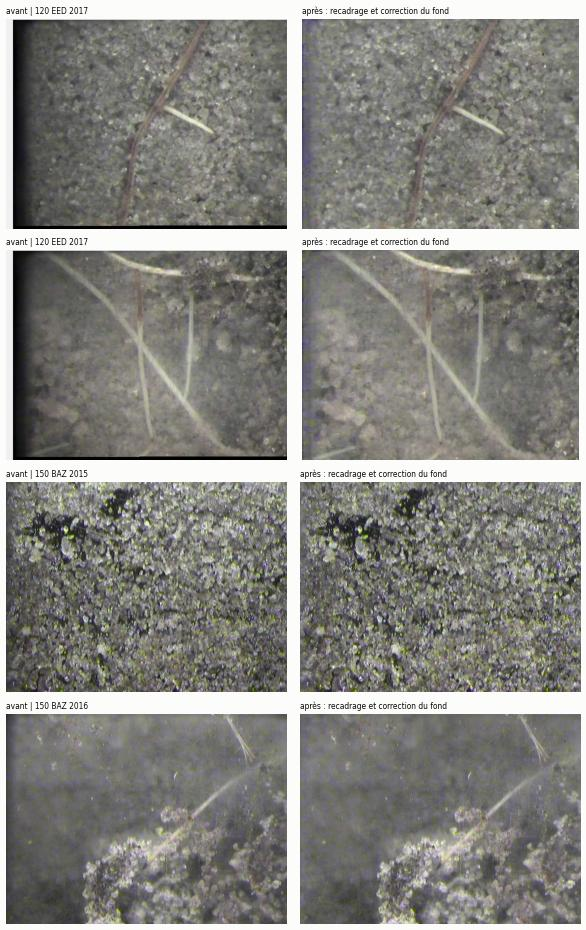

In [6]:
flats = {g: flatfield(means[g], crop_for(int(g.split()[0]))) for g in G}

# Images courantes (ni orangées, ni saturées, ni en gris) : 2 en 120 DPI, 1 par campagne BAZ en 150 DPI
ok = d[(d['clip_high'] < 0.01) & (d['rb_ratio'] < 1.3) & (d['chroma'] >= 5)]
ex = pd.concat([ok[ok['group'] == g].sample(n, random_state=3)
                for g, n in [('120 EED 2017', 2), ('150 BAZ 2015', 1), ('150 BAZ 2016', 1)]])
fig, axes = plt.subplots(len(ex), 2, figsize=(10, 3.9 * len(ex)))
for row, (_, x) in zip(axes, ex.iterrows()):
    img = np.asarray(Image.open(RAW / x['image_path']).convert('RGB'))
    row[0].imshow(img)
    row[0].set_title(f"avant | {x['group']}", loc='left', fontsize=9)
    row[1].imshow(preprocess(img, flats[x['group']], crop_for(x['dpi'])))
    row[1].set_title('après : recadrage et correction du fond', loc='left', fontsize=9)
    for ax in row:
        ax.axis('off')
fig.tight_layout()
viz.save(fig, '01_pretraitement_avant_apres.jpg')

In [7]:
# Vérification sur 150 images par groupe, tirées dans le val (hors du train qui a servi à calculer le fond)
def profiles(group, n=150):
    sub = d[(d['group'] == group) & (d['split'] == 'val')].sample(n, random_state=0)
    crop = crop_for(int(sub['dpi'].iloc[0]))
    before = np.array([np.asarray(Image.open(RAW / p).convert('L'), dtype=float)[crop] for p in sub['image_path']])
    after = np.clip(before / flats[group], 0, 255)
    third = before.shape[2] // 3
    ratio = lambda a: a[:, :, :third].mean((1, 2)) / a[:, :, -third:].mean((1, 2))  # tiers gauche / tiers droit
    return {'before': before.mean((0, 1)), 'after': after.mean((0, 1)),
            'ratio_before': ratio(before), 'ratio_after': ratio(after)}


prof = {g: profiles(g) for g in G}
pd.DataFrame({
    'avant (médiane)': {g: np.median(p['ratio_before']) for g, p in prof.items()},
    'avant (centile 5)': {g: np.percentile(p['ratio_before'], 5) for g, p in prof.items()},
    'avant (centile 95)': {g: np.percentile(p['ratio_before'], 95) for g, p in prof.items()},
    'après (médiane)': {g: np.median(p['ratio_after']) for g, p in prof.items()},
    'après (centile 5)': {g: np.percentile(p['ratio_after'], 5) for g, p in prof.items()},
    'après (centile 95)': {g: np.percentile(p['ratio_after'], 95) for g, p in prof.items()},
}).loc[G].round(2)

,avant (médiane),avant (centile 5),avant (centile 95),après (médiane),après (centile 5),après (centile 95)
150 BAZ 2015,0.96,0.81,1.16,0.98,0.82,1.19
150 BAZ 2016,0.96,0.84,1.13,1.01,0.88,1.19
150 CZ 2016,0.96,0.83,1.13,1.01,0.88,1.19
120 EED 2017,0.69,0.59,0.80,0.98,0.83,1.13


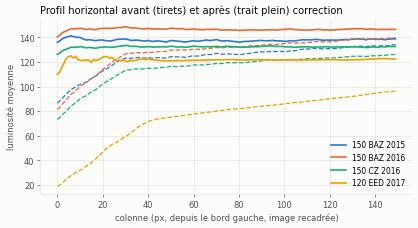

In [8]:
fig, ax = plt.subplots(figsize=(8, 3.8))
for g in G:
    c = viz.GROUP_COLORS[g]
    ax.plot(prof[g]['before'][:150], color=c, lw=1.5, ls='--')
    ax.plot(prof[g]['after'][:150], color=c, lw=2, label=g)
ax.set_xlabel('colonne (px, depuis le bord gauche, image recadrée)')
ax.set_ylabel('luminosité moyenne')
ax.set_title('Profil horizontal avant (tirets) et après (trait plein) correction', loc='left')
ax.legend(frameon=False, fontsize=9)
viz.save(fig, '01_profils_avant_apres.png')

**Bilan** : le prétraitement fonctionne.
- Dégradé gauche / droite corrigé : le 120 DPI, le plus touché, passe d'un côté gauche nettement plus sombre à un éclairage uniforme ; le 150 DPI, déjà proche de l'uniforme, change peu.
- Colonnes 19 à 23 du 120 DPI retirées en plus : trop sombres et bruitées après correction, presque jamais annotées.

Vérifié sur des images du val, hors du train utilisé pour calculer le fond.

Limites :
- une moyenne par groupe ne corrige pas les écarts propres à chaque image (sol, lumière) : normalisation par image nécessaire ensuite ;
- une légère teinte bleutée peut rester au bord gauche du 120 DPI.

## 3. Couleur : gris ou RGB ?

In [9]:
g = d.groupby('group')
pd.DataFrame({
    'écart entre canaux, médiane (niveaux sur 255)': g['chroma'].median().round(1),
    'images quasi grises (écart < 5), %': (100 * g['chroma'].apply(lambda s: (s < 5).mean())).round(1),
    'R/B, médiane (1 = neutre)': g['rb_ratio'].median().round(2),
    'images orangées (R/B > 1,3), %': (100 * g['rb_ratio'].apply(lambda s: (s > 1.3).mean())).round(1),
}).loc[G]

,"écart entre canaux, médiane (niveaux sur 255)","images quasi grises (écart < 5), %","R/B, médiane (1 = neutre)","images orangées (R/B > 1,3), %"
group,,,,
150 BAZ 2015,16.5,0.2,1.05,12.5
150 BAZ 2016,13.4,20.1,1.03,0.3
150 CZ 2016,11.0,0.0,1.04,0.0
120 EED 2017,6.9,17.3,1.04,21.8


- **Écart entre canaux** : canal le plus fort moins le plus faible, par pixel, en niveaux sur 255 (0 = gris).
- **Quasi gris** : écart moyen inférieur à 5 sur 255, couleurs imperceptibles.
- **R/B** : rouge moyen divisé par bleu moyen (1 = neutre, au-dessus de 1 = orangé).

Images peu colorées, neutres en médiane. Orange : surtout le 120 DPI (22 %) et BAZ 2015 (12,5 %). Gris : BAZ 2016 (20 %) et le 120 DPI (17 %). CZ 2016 : ni l'un ni l'autre. Ces écarts tiennent à des sessions précises (tableaux suivants).

In [10]:
# Part d'images orangées et quasi grises par session (date)
s = d.assign(orange=d['rb_ratio'] > 1.3, gris=d['chroma'] < 5)
s.groupby(['group', 'date'])[['orange', 'gris']].mean().round(2).query('orange > 0.1 or gris > 0.1')

orange  gris
group        date                    
120 EED 2017 2017-06-08    0.37  0.12
             2017-06-29    0.04  0.24
             2017-07-13    0.00  0.22
             2017-07-27    0.05  0.33
             2017-08-17    0.81  0.01
150 BAZ 2015 2015-05-28    0.35  0.01
             2015-06-25    0.99  0.00
             2015-07-22    0.26  0.00
150 BAZ 2016 2016-06-07    0.00  0.34
             2016-07-18    0.00  0.50
             2016-07-25    0.00  0.51

In [11]:
# 120 DPI : part d'images orangées selon l'heure de prise de vue
x = s[s['dpi'] == 120].assign(heure=lambda t: t['time'].str[:2].astype(int))
x.groupby('heure')['orange'].agg(['mean', 'size']).round(2).T

heure,6,7,8,9,10,11,12,13,14,15,16
mean,0.42,0.35,0.33,0.29,0.26,0.07,0.1,0.0,0.0,0.0,0.0
size,375.00,1921.00,2889.00,3074.00,2786.00,2651.00,1417.0,737.0,457.0,412.0,323.0


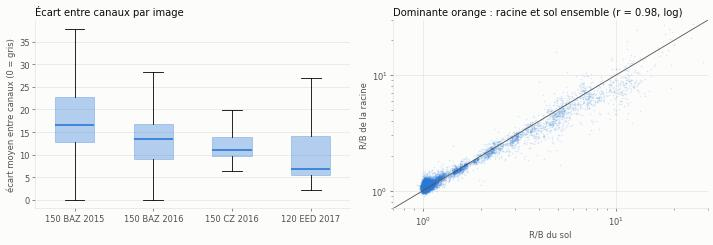

In [12]:
r = d.dropna(subset=['d_gray'])
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
axes[0].boxplot([d.loc[d['group'] == k, 'chroma'] for k in G], tick_labels=G, widths=0.5, showfliers=False,
                patch_artist=True, boxprops=dict(facecolor=viz.ACCENT, edgecolor=viz.ACCENT, alpha=0.35),
                medianprops=dict(color=viz.ACCENT, linewidth=2))
axes[0].set_ylabel('écart moyen entre canaux (0 = gris)')
axes[0].set_title('Écart entre canaux par image', loc='left')
axes[0].grid(axis='x', visible=False)
axes[1].scatter(r['rb_soil'], r['rb_root'], s=4, alpha=0.15, color=viz.ACCENT, linewidths=0)
lim = [0.7, 30]
axes[1].plot(lim, lim, color=viz.INK_2, lw=1)
axes[1].set(xscale='log', yscale='log', xlim=lim, ylim=lim, xlabel='R/B du sol', ylabel='R/B de la racine')
c = np.corrcoef(np.log(r['rb_soil']), np.log(r['rb_root']))[0, 1]
axes[1].set_title(f'Dominante orange : racine et sol ensemble (r = {c:.2f}, log)', loc='left')
fig.tight_layout()
viz.save(fig, '01_couleur.png')

In [13]:
# Question : si on réduit chaque pixel à UN seul nombre, quelle conversion distingue le mieux racine et sol ?
# Sur 200 images par groupe : pixels de racine (cœur du masque) contre pixels de sol (à plus de 5 px du masque).
# Score |d'| = écart des moyennes racine / sol divisé par leur écart-type commun.
#   vers 1 : les deux se chevauchent beaucoup ; 2 et plus : bien séparés ; plus grand = mieux.
# Conversions comparées :
#   gris = luminosité ; max des canaux = le plus fort de R, G, B ; rouge seul = canal R ;
#   couleur, combinaison fixe = a R + b G + c B, un seul jeu de poids appris sur la moitié des images, testé sur l'autre ;
#   couleur, optimum par image = idem, poids ajustés image par image avec son masque (plafond, inutilisable tel quel).
# Relit 800 images sur la clé, environ 1 min.
conv, w = compare_conversions(d)
print('combinaison fixe (R, G, B normalisés par image) :', w.round(2))
cols = ['gris', 'max des canaux', 'rouge seul', 'couleur, combinaison fixe', 'couleur, optimum par image']
conv.groupby('group')[cols].median().loc[G].round(2)

combinaison fixe (R, G, B normalisés par image) : [ 0.58 -0.29 -0.13]


,gris,max des canaux,rouge seul,"couleur, combinaison fixe","couleur, optimum par image"
group,,,,,
150 BAZ 2015,1.16,1.18,1.24,1.28,1.71
150 BAZ 2016,1.00,1.02,1.10,1.26,1.67
150 CZ 2016,1.30,1.34,1.40,1.76,2.07
120 EED 2017,1.55,1.62,1.61,1.80,2.06


- Gris, max des canaux et rouge seul : séparation faible (1,0 à 1,6 selon le groupe).
- Un mélange de couleurs fixe fait mieux (environ 20 % de plus en médiane), surtout là où la luminosité sépare mal (BAZ 2016). Les poids donnent beaucoup de rouge : les racines sont un peu plus rouges que le sol.
- Un mélange adapté à chaque image sépare nettement mieux (1,7 à 2,1) : la couleur contient de l'information, mais le bon mélange change d'une image à l'autre (sol, éclairage). C'est un plafond, pas une méthode : il faut le masque pour le calculer.
- Garder les 3 canaux laisse au modèle la possibilité d'apprendre un mélange adapté ; le gris l'écarte.

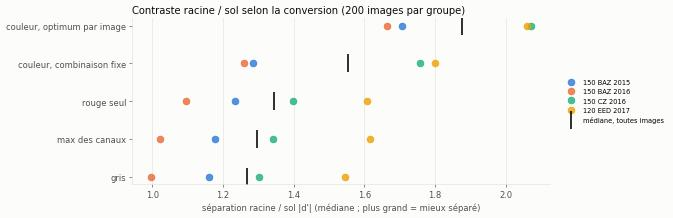

In [14]:
med = conv[cols].median()
fig, ax = plt.subplots(figsize=(9, 3.6))
for k in G:
    ax.plot(conv.loc[conv['group'] == k, cols].median(), range(len(cols)), 'o', color=viz.GROUP_COLORS[k],
            markersize=8, alpha=0.8, label=k)
ax.plot(med, range(len(cols)), '|', color=viz.INK, markersize=22, mew=2, label='médiane, toutes images')
ax.set_yticks(range(len(cols)), cols)
ax.set_xlabel("séparation racine / sol |d'| (médiane ; plus grand = mieux séparé)")
ax.set_title('Contraste racine / sol selon la conversion (200 images par groupe)', loc='left')
ax.grid(axis='y', visible=False)
ax.legend(frameon=False, fontsize=8, loc='center left', bbox_to_anchor=(1.02, 0.5))
viz.save(fig, '01_contraste_racine_sol.png')

- Images peu colorées : écart médian entre canaux de 7 à 16 sur 255.
- Dominante orange = effet de session, pas de sol :
  - 25/06/2015 : 99 % des images ; 17/08/2017 : 81 % ; 08/06/2017 : 37 % ; quasi nulle les autres jours ;
  - 120 DPI : 30 à 40 % des images avant 10 h, aucune après 13 h ;
  - racine et sol touchés ensemble (r = 0,98) → artefact d'acquisition (balance des blancs, lumière).
- Sessions en niveaux de gris : 18 et 25/07/2016 (environ 50 %), 07/06/2016 (34 %) ; 120 DPI (17 %).
- Séparation racine / sol (|d'| médian) : gris 1,27 ; rouge 1,34 ; combinaison couleur fixe 1,55 (+20 %). La teinte apporte une information réelle, une fois la dominante retirée (racines un peu plus rouges que le sol).
- Limites : séparation pixel par pixel, sans forme ni texture (que le U-Net exploitera) ; masques d'origine imparfaits ; « sol » = tout le reste, racines non annotées comprises.

**Décision à trancher** :
- garder 3 canaux, normalisés canal par canal et par image (efface la dominante, garde la teinte) ;
- ou passer en gris (plus simple, perte d'environ 20 % de séparation au niveau du pixel).
- Pas de gain de calcul notable avec le gris : seule la première couche du U-Net voit les canaux.
- Dans les deux cas : désaturation aléatoire à l'entraînement (sessions grises).

## 4. Exposition et dynamique

In [15]:
pd.DataFrame({
    'luminosité, médiane (0-255)': g['lum_mean'].median().round(0),
    'centile 1, médiane (0-255)': g['lum_p1'].median().round(0),
    'centile 99, médiane (0-255)': g['lum_p99'].median().round(0),
    'images avec > 1 % de pixels saturés, %': (100 * g['clip_high'].apply(lambda s: (s > 0.01).mean())).round(1),
    'images avec > 1 % de pixels noirs, %': (100 * g['clip_low'].apply(lambda s: (s > 0.01).mean())).round(1),
}).loc[G]

,"luminosité, médiane (0-255)","centile 1, médiane (0-255)","centile 99, médiane (0-255)","images avec > 1 % de pixels saturés, %","images avec > 1 % de pixels noirs, %"
group,,,,,
150 BAZ 2015,118.0,59.0,227.0,36.6,0.0
150 BAZ 2016,128.0,71.0,213.0,16.1,0.0
150 CZ 2016,119.0,66.0,204.0,1.8,0.0
120 EED 2017,106.0,14.0,176.0,5.7,0.4


Pixel saturé : au moins un canal à 254 ou 255 (information perdue) ; pixel noir : les trois canaux à 2 ou moins.

120 DPI plus sombre (centile 1 médian de 14 contre 59 à 71 en 150 DPI). Saturation surtout en BAZ 2015 (37 %) et BAZ 2016 (16 %) : vraies surexpositions (sol clair, reflets, gouttes), même en écartant les images orangées (35 % en BAZ 2015) ; sur ces zones, racine et sol deviennent blancs. Pixels noirs : négligeables.

In [16]:
# Effet de la profondeur sur la luminosité
prof = pd.cut(d['position'], [0, 35, 70, 200], labels=['haut (1-35)', 'milieu (36-70)', 'bas (71+)'])
d.assign(profondeur=prof).pivot_table('lum_mean', 'group', 'profondeur', 'median', observed=True).loc[G].round(1)

profondeur,haut (1-35),milieu (36-70),bas (71+)
group,,,
150 BAZ 2015,117.3,116.1,126.7
150 BAZ 2016,122.0,129.0,134.7
150 CZ 2016,118.2,118.8,119.8
120 EED 2017,105.8,106.1,106.5


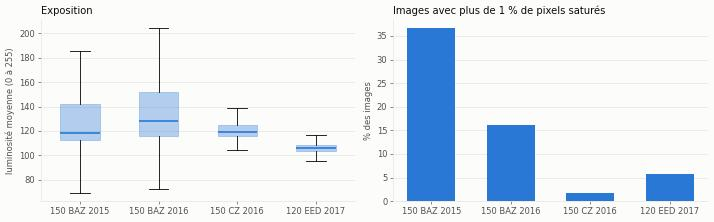

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].boxplot([d.loc[d['group'] == k, 'lum_mean'] for k in G], tick_labels=G, widths=0.5, showfliers=False,
                patch_artist=True, boxprops=dict(facecolor=viz.ACCENT, edgecolor=viz.ACCENT, alpha=0.35),
                medianprops=dict(color=viz.ACCENT, linewidth=2))
axes[0].set_ylabel('luminosité moyenne (0 à 255)')
axes[0].set_title('Exposition', loc='left')
axes[0].grid(axis='x', visible=False)
sat = g['clip_high'].apply(lambda s: 100 * (s > 0.01).mean()).loc[G]
axes[1].bar(G, sat, color=viz.ACCENT, width=0.6)
axes[1].set_ylabel('% des images')
axes[1].set_title('Images avec plus de 1 % de pixels saturés', loc='left')
axes[1].grid(axis='x', visible=False)
fig.tight_layout()
viz.save(fig, '01_exposition.png')

- 120 DPI plus sombre : centile 1 médian de 14, contre 59 à 71 en 150 DPI.
- BAZ 2015 : 37 % des images avec plus de 1 % de pixels saturés (sol clair, gouttes sur la paroi, voir section 5).
- Profondeur : effet faible (BAZ 2016 : 122 en haut, 135 en bas ; nul ailleurs).

**Décision** : normalisation par image, étirement entre les centiles 1 et 99 (robuste aux pixels saturés). Pas de CLAHE a priori.

## 5. Netteté, entrelacement, défauts de paroi

In [18]:
pd.DataFrame({
    'netteté (médiane)': g['sharpness'].median(),
    'netteté (centile 5)': g['sharpness'].quantile(0.05),
    'netteté (centile 95)': g['sharpness'].quantile(0.95),
    'entrelacement (médiane)': g['comb'].median(),
}).loc[G].round(2)

,netteté (médiane),netteté (centile 5),netteté (centile 95),entrelacement (médiane)
group,,,,
150 BAZ 2015,297.09,55.59,952.35,0.55
150 BAZ 2016,156.72,44.01,397.83,0.54
150 CZ 2016,95.78,33.20,220.23,0.54
120 EED 2017,108.45,31.01,296.65,0.58


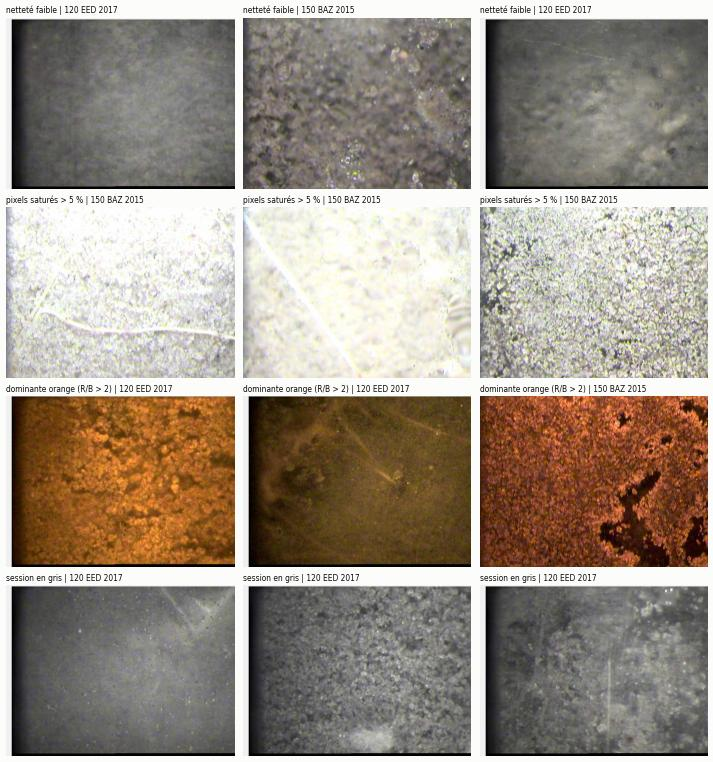

In [19]:
# Exemples : flou ou buée, surexposition, dominante orange, session en gris
cases = {
    'netteté faible': d[d['sharpness'] <= d.groupby('group')['sharpness'].transform(lambda s: s.quantile(0.02))],
    'pixels saturés > 5 %': d[d['clip_high'] > 0.05],
    'dominante orange (R/B > 2)': d[d['rb_ratio'] > 2],
    'session en gris': d[d['chroma'] < 5],
}
fig, axes = plt.subplots(len(cases), 3, figsize=(12, 3.2 * len(cases)))
for row, (name, sub) in zip(axes, cases.items()):
    for ax, (_, x) in zip(row, sub.sample(3, random_state=1).iterrows()):
        ax.imshow(Image.open(RAW / x['image_path']))
        ax.set_title(f"{name} | {x['group']}", loc='left', fontsize=9)
        ax.axis('off')
fig.tight_layout()
viz.save(fig, '01_exemples_defauts.jpg')

- Netteté (variance du laplacien) très variable : médiane de 96 à 297 selon le groupe. Valeurs basses = buée, flou, mais aussi sol homogène avec racines nettes → indicateur seul non fiable.
- Entrelacement : non détecté (rapport lignes voisines / lignes à 2 d'écart de 0,54 à 0,58, inférieur à 1).
- Gouttes d'eau et buée sur la paroi du tube, fréquentes en BAZ 2015 (vu, non quantifié).

**Décision** : pas de filtre automatique sur la netteté ni sur l'exposition ; inclure ces cas dans les images annotées et dans le test.

## 6. Synthèse : prétraitements proposés

Dans l'ordre :

1. **Recadrage** du 120 DPI : lignes 4 à 471, colonnes 24 à 639. Mêmes indices sur les masques.
2. **Correction de fond** : division par l'image moyenne lissée du groupe, gain plafonné à ×8 (vignettage du 120 DPI, bord gauche et dégradé vertical du 150 DPI).
3. **Normalisation par image** : étirement entre les centiles 1 et 99, canal par canal (efface la dominante orange et les écarts d'exposition).
4. **Couleur** : 3 canaux normalisés (gain d'environ 20 % de séparation racine / sol) ou gris. À trancher.
5. **Pas de filtre** sur la netteté ni l'exposition. Augmentations à l'entraînement : luminosité, contraste, désaturation.

Points de vigilance pour le choix des images à annoter : sessions orangées (25/06/2015, 17/08/2017), sessions en gris (juillet 2016), buée, gouttes, surexposition (BAZ 2015).